In [ ]:
import pandas as pd
import  numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
import gdown

In [ ]:
pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")


In [ ]:
file_id = "1gc7znH4EofC1QtevY5gXTeodzF8d2Ih_"
url = f"https://drive.google.com/uc?id={file_id}"

gdown.download(url, "german_Credit_final.csv", quiet=False)



df = pd.read_csv("german_Credit_final.csv", index_col = 0)

Downloading...
From: https://drive.google.com/uc?id=1gc7znH4EofC1QtevY5gXTeodzF8d2Ih_
To: /content/german_Credit_final.csv
100%|██████████| 53.4k/53.4k [00:00<00:00, 37.1MB/s]


In [ ]:
!head -c 500 data.csv

head: cannot open 'data.csv' for reading: No such file or directory


In [ ]:
df.head()

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad


In [ ]:
df["Risk"].value_counts()

,count
Risk,
good,700
bad,300


In [ ]:
df.shape

(1000, 10)

In [ ]:
df.describe(include= "all"). T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,1000.0,NaN,NaN,NaN,35.546,11.375469,19.0,27.0,33.0,42.0,75.0
Sex,1000,2,male,690,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Job,1000.0,NaN,NaN,NaN,1.904,0.653614,0.0,2.0,2.0,2.0,3.0
Housing,1000,3,own,713,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Saving accounts,817,4,little,603,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Checking account,606,3,little,274,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Credit amount,1000.0,NaN,NaN,NaN,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
Duration,1000.0,NaN,NaN,NaN,20.903,12.058814,4.0,12.0,18.0,24.0,72.0
Purpose,1000,8,car,337,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Risk,1000,2,good,700,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
df["Job"].unique()

array([2, 1, 3, 0])

In [ ]:
for i in df.columns:
  if i =='Credit amount' or i == 'Age':
    continue
  else:
    print(i)
    print(df[i].unique())

Sex
['male' 'female']
Job
[2 1 3 0]
Housing
['own' 'free' 'rent']
Saving accounts
[nan 'little' 'quite rich' 'rich' 'moderate']
Checking account
['little' 'moderate' nan 'rich']
Duration
[ 6 48 12 42 24 36 30 15  9 10  7 60 18 45 11 27  8 54 20 14 33 21 16  4
 47 13 22 39 28  5 26 72 40]
Purpose
['radio/TV' 'education' 'furniture/equipment' 'car' 'business'
 'domestic appliances' 'repairs' 'vacation/others']
Risk
['good' 'bad']


In [ ]:
df.isna().sum()

,0
Age,0
Sex,0
Job,0
Housing,0
Saving accounts,183
Checking account,394
Credit amount,0
Duration,0
Purpose,0
Risk,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df = df.dropna().reset_index(drop = True)

In [ ]:
df

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,22,female,2,own,little,moderate,5951,48,radio/TV,bad
1,45,male,2,free,little,little,7882,42,furniture/equipment,good
2,53,male,2,free,little,little,4870,24,car,bad
3,35,male,3,rent,little,moderate,6948,36,car,good
4,28,male,3,own,little,moderate,5234,30,car,bad
...,...,...,...,...,...,...,...,...,...,...
517,48,male,1,own,little,moderate,1743,24,radio/TV,good
518,30,male,3,own,little,little,3959,36,furniture/equipment,good
519,40,male,3,own,little,little,3857,30,car,good
520,23,male,2,free,little,little,1845,45,radio/TV,bad


In [ ]:
df.columns

Index(['Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account',
       'Credit amount', 'Duration', 'Purpose', 'Risk'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 522 entries, 0 to 521
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Age               522 non-null    int64 
 1   Sex               522 non-null    object
 2   Job               522 non-null    int64 
 3   Housing           522 non-null    object
 4   Saving accounts   522 non-null    object
 5   Checking account  522 non-null    object
 6   Credit amount     522 non-null    int64 
 7   Duration          522 non-null    int64 
 8   Purpose           522 non-null    object
 9   Risk              522 non-null    object
dtypes: int64(4), object(6)
memory usage: 40.9+ KB


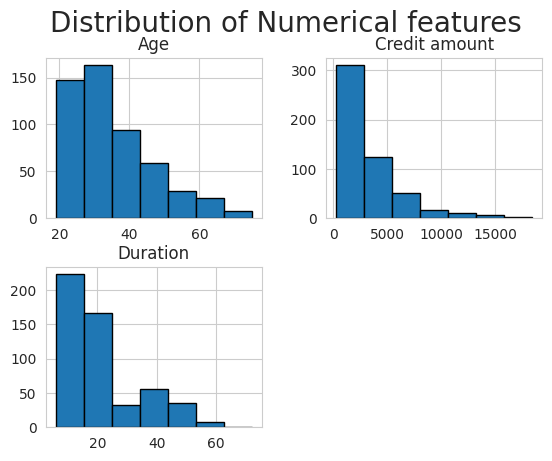

In [ ]:
df[['Age', 'Credit amount', 'Duration']].hist(bins = 7 , edgecolor = "black")
plt.suptitle("Distribution of Numerical features", fontsize = 20)
plt.show()

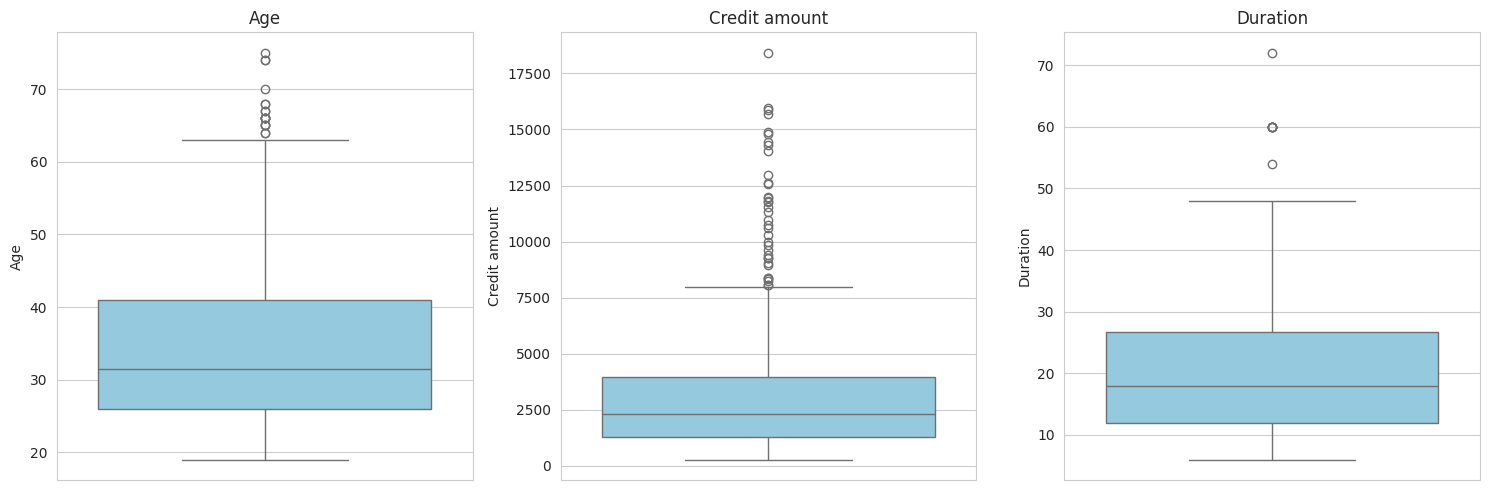

In [ ]:
plt.figure(figsize= (15,5))
for i , col in enumerate(['Age', 'Credit amount', 'Duration']):
  plt.subplot(1,3,i+1)
  sns.boxplot(y =df[col], color = "skyblue")
  plt.title(col)

plt.tight_layout()
plt.show()

In [ ]:
df.query("Duration >= 70")

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
358,24,male,2,own,moderate,moderate,5595,72,radio/TV,bad


In [ ]:
df.query("Duration >= 60")

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
18,63,male,2,own,little,little,6836,60,business,bad
176,24,female,3,own,moderate,moderate,7408,60,car,bad
199,60,female,3,free,moderate,moderate,14782,60,vacation/others,bad
358,24,male,2,own,moderate,moderate,5595,72,radio/TV,bad
378,27,male,3,own,little,moderate,14027,60,car,bad
489,42,male,2,free,little,moderate,6288,60,education,bad
507,36,male,2,rent,little,little,7297,60,business,bad


In [ ]:
categorical_cols = ["Sex" , "Job", "Housing", "Saving accounts", "Checking account", "Purpose"]

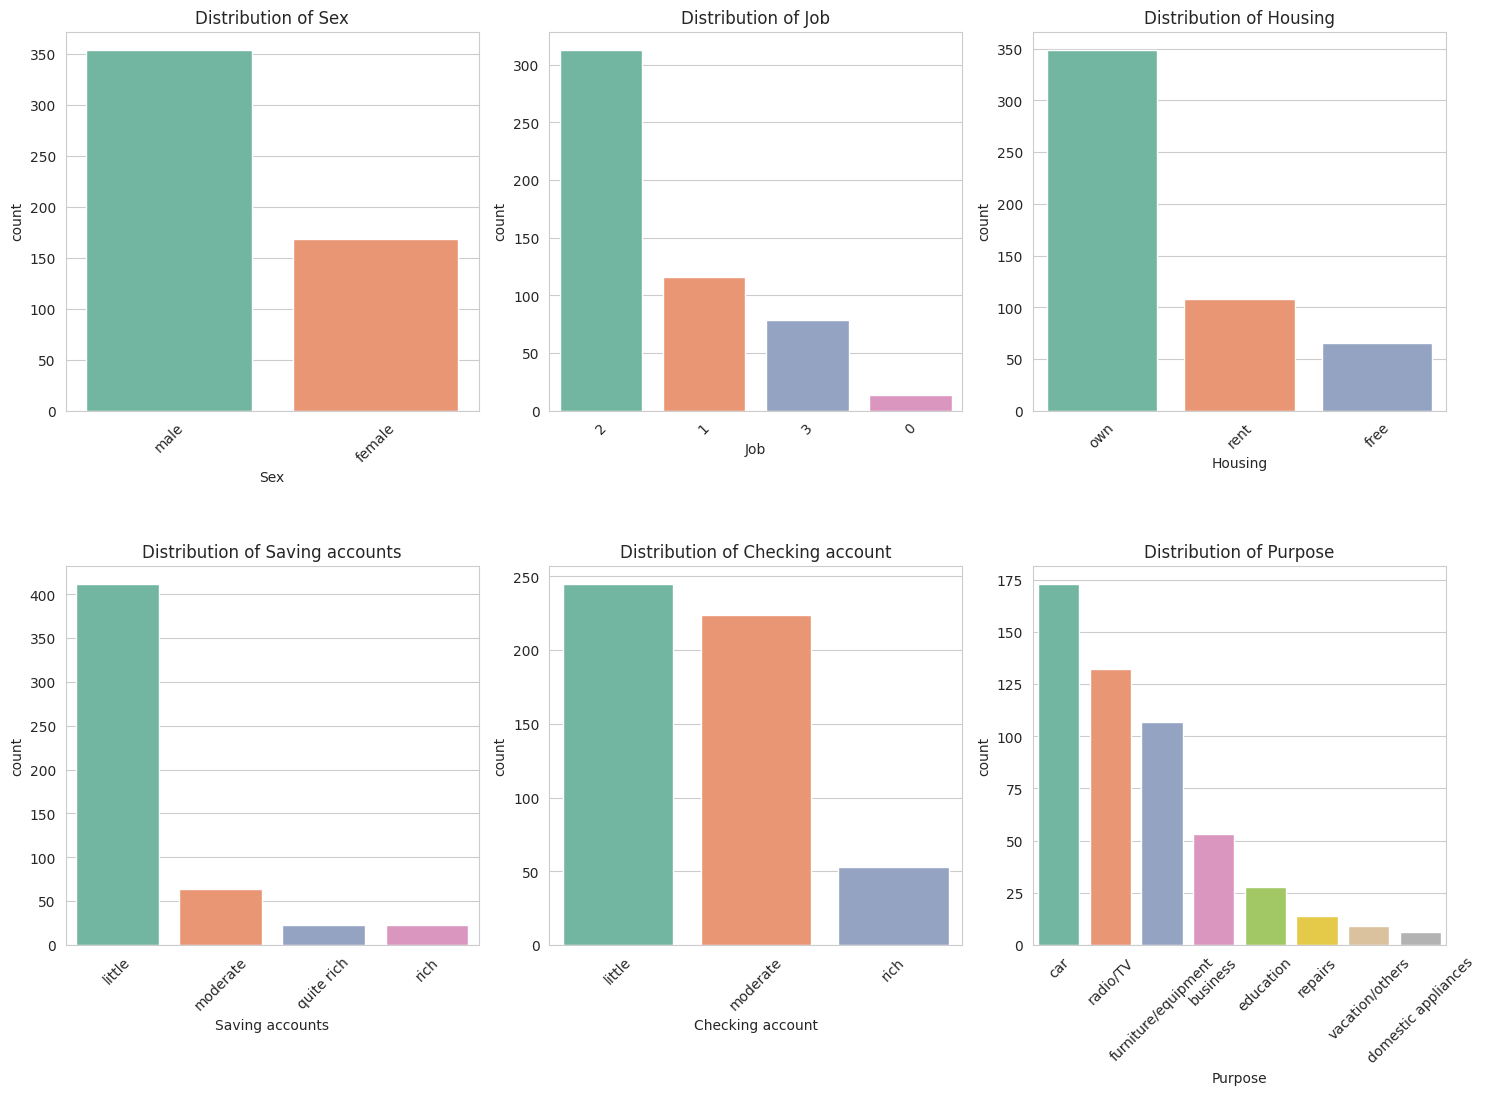

In [ ]:
plt.figure(figsize= (15,15))

for i, col in enumerate(categorical_cols):
  plt.subplot(3,3,i+1)
  sns.countplot(data = df, x = col, palette= "Set2", order = df[col].value_counts().index)
  plt.title(f"Distribution of {col}")
  plt.xticks(rotation = 45)

plt.tight_layout()
plt.show()


In [ ]:
values = df["Purpose"].value_counts()
values
labels = values.index
labels

Index(['car', 'radio/TV', 'furniture/equipment', 'business', 'education',
       'repairs', 'vacation/others', 'domestic appliances'],
      dtype='object', name='Purpose')

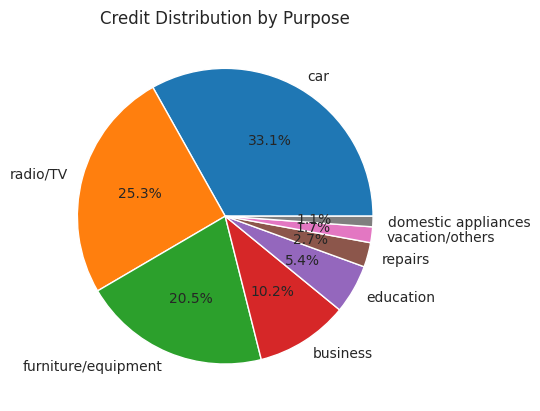

In [ ]:

plt.pie(values, labels=labels, autopct='%1.1f%%')
plt.title("Credit Distribution by Purpose")
plt.show()


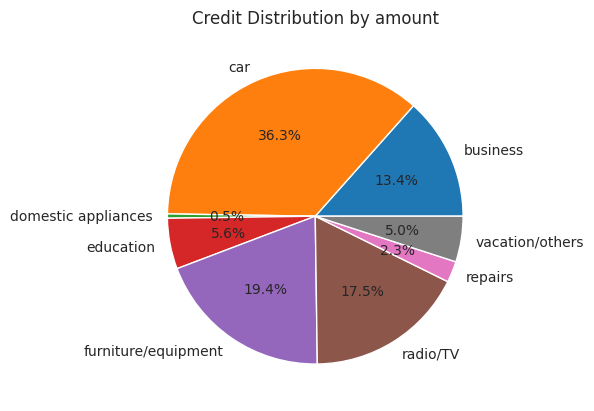

In [ ]:
values = df.groupby(["Purpose"])["Credit amount"].sum()
values
labels = values.index
labels

plt.pie(values, labels=labels, autopct='%1.1f%%')
plt.title("Credit Distribution by amount")
plt.show()

In [ ]:
corr = df[["Age", "Job", "Credit amount", "Duration"]].corr()

In [ ]:
corr

,Age,Job,Credit amount,Duration
Age,1.000000,0.039771,0.082014,0.001549
Job,0.039771,1.000000,0.334721,0.200794
Credit amount,0.082014,0.334721,1.000000,0.613298
Duration,0.001549,0.200794,0.613298,1.000000


<Axes: >

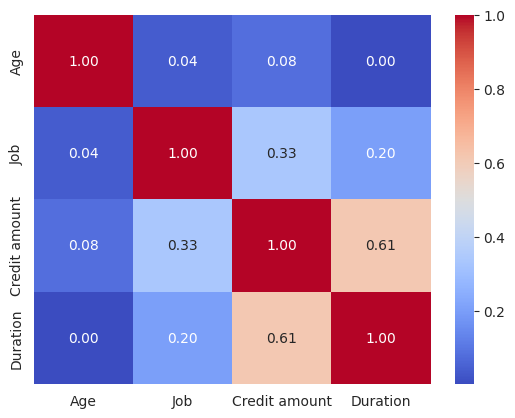

In [ ]:
sns.heatmap(corr, annot = True, cmap = "coolwarm",fmt  = ".2f" )

In [ ]:
df.groupby("Job")["Credit amount"].mean()

,Credit amount
Job,
0,1767.857143
1,2250.715517
2,3129.130990
3,5648.784810


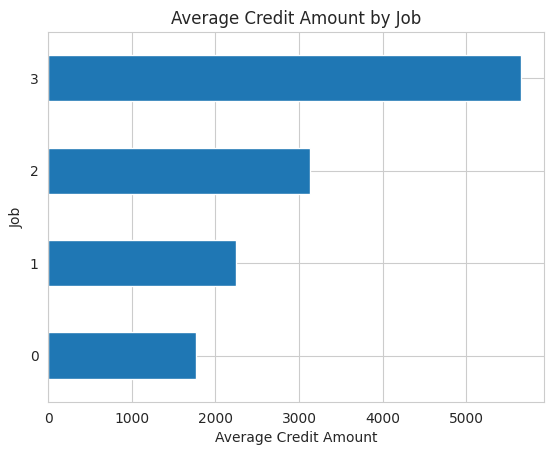

In [ ]:
values = df.groupby("Job")["Credit amount"].mean()

values.plot(kind="barh")

plt.title("Average Credit Amount by Job")
plt.xlabel("Average Credit Amount")
plt.ylabel("Job")
plt.show()

In [ ]:
df.groupby("Sex")["Credit amount"].mean()

,Credit amount
Sex,
female,2937.202381
male,3440.833333


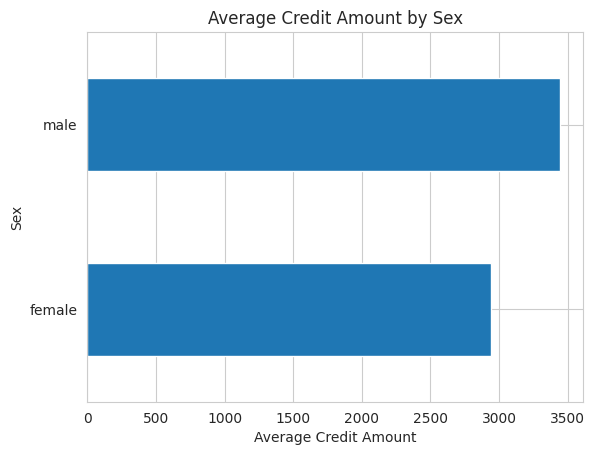

In [ ]:
values = df.groupby("Sex")["Credit amount"].mean()

values.plot(kind="barh")

plt.title("Average Credit Amount by Sex")
plt.xlabel("Average Credit Amount")
plt.ylabel("Sex")
plt.show()

In [ ]:
df["Purpose"].unique()

array(['radio/TV', 'furniture/equipment', 'car', 'business',
       'domestic appliances', 'repairs', 'vacation/others', 'education'],
      dtype=object)

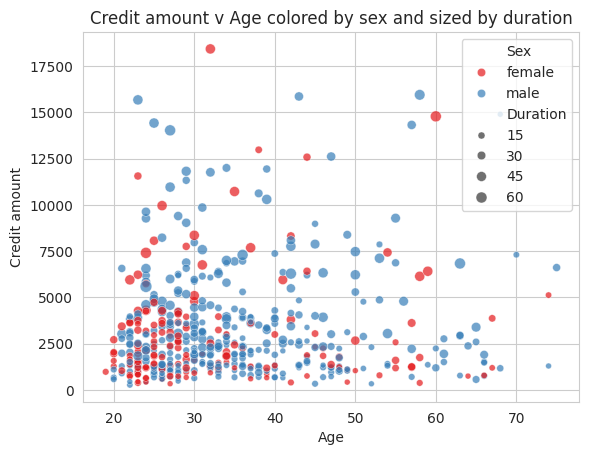

In [ ]:
sns.scatterplot(data =df , x = "Age", y = "Credit amount", hue = "Sex", size = "Duration", alpha = 0.7 ,palette = "Set1" )
plt.title("Credit amount v Age colored by sex and sized by duration")
plt.show()

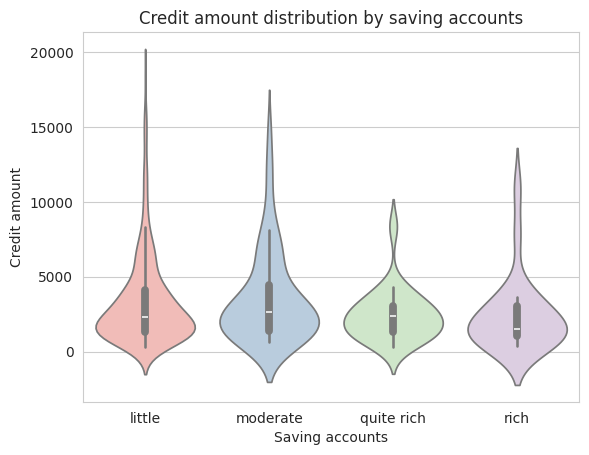

In [ ]:
sns.violinplot(data = df, x = "Saving accounts", y = "Credit amount", palette = "Pastel1")
plt.title("Credit amount distribution by saving accounts")
plt.show()

In [ ]:
df["Risk"].value_counts(normalize = True) * 100

,proportion
Risk,
good,55.747126
bad,44.252874


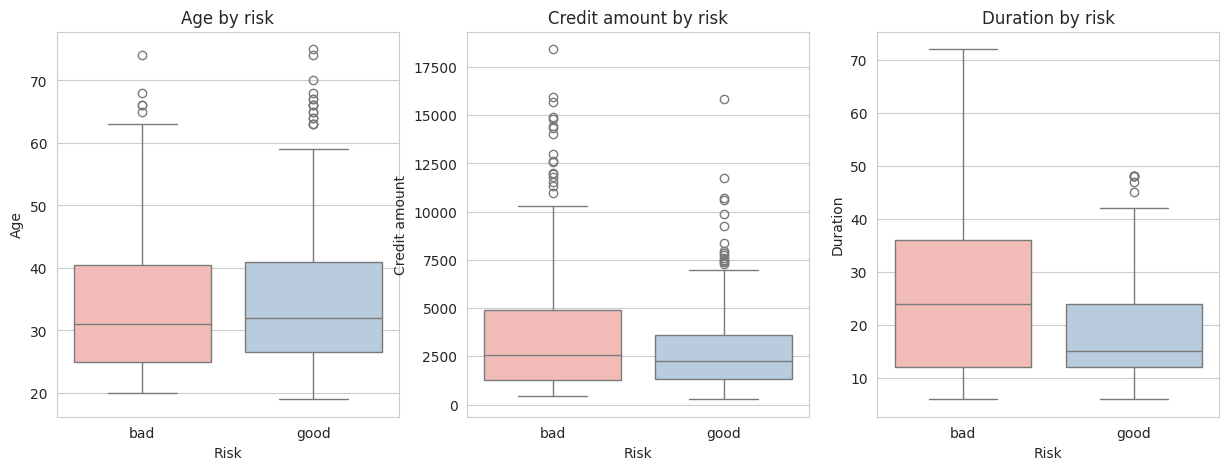

In [ ]:
plt.figure(figsize= (15,5))
for i , col in enumerate(["Age", "Credit amount", "Duration"]):
  plt.subplot(1,3,i+1)
  sns.boxplot(data = df,x = df["Risk"], y = col, palette = "Pastel1")
  plt.title(f"{col} by risk")
  plt.figure

In [ ]:
df.groupby("Risk")[["Age", "Credit amount", "Duration"]].mean()

,Age,Credit amount,Duration
Risk,,,
bad,34.147186,3881.090909,25.445887
good,35.477663,2800.594502,18.079038


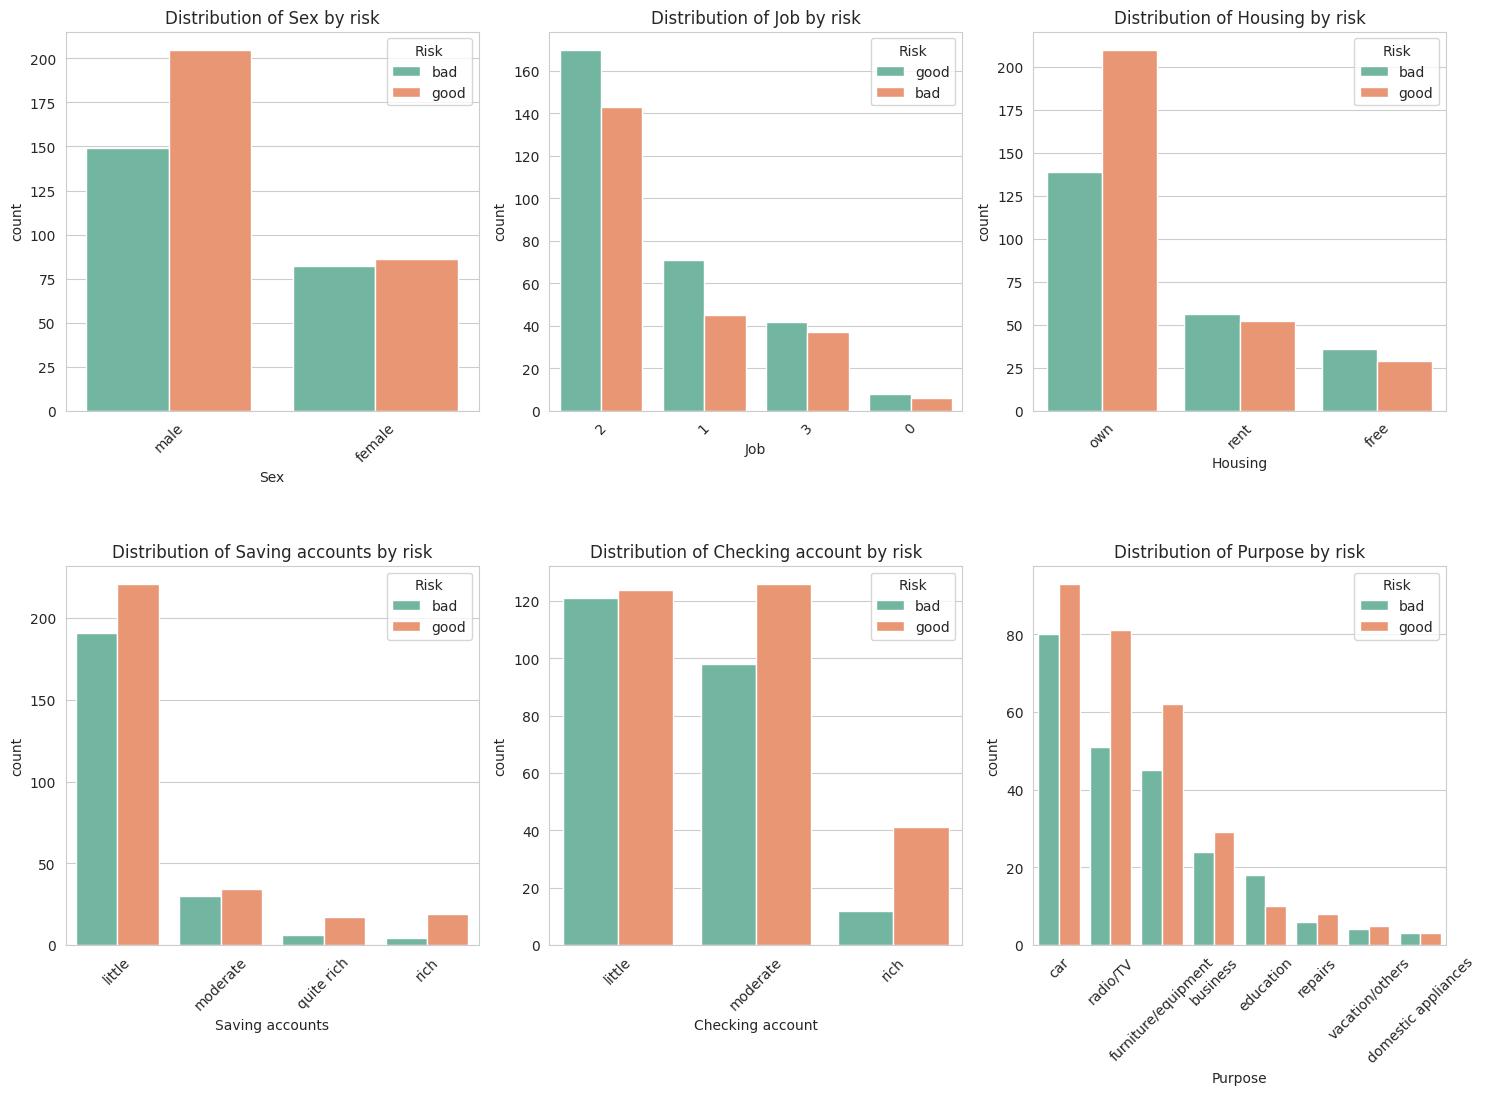

In [ ]:
plt.figure(figsize= (15,15))

for i , col in enumerate(categorical_cols):
  plt.subplot(3,3,i+1)
  sns.countplot(data = df, x = col, hue = "Risk", palette= "Set2", order = df[col].value_counts().index)
  plt.title(f"Distribution of {col} by risk")
  plt.xticks(rotation = 45)

plt.tight_layout()
plt.show()

In [ ]:
#feature engineering

In [ ]:
df.columns

Index(['Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account',
       'Credit amount', 'Duration', 'Purpose', 'Risk'],
      dtype='object')

In [ ]:
features = ['Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account',
        'Credit amount', 'Duration']
target =  'Risk'


df_model = df[features + [target]].copy()
df_model.head()

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Risk
0,22,female,2,own,little,moderate,5951,48,bad
1,45,male,2,free,little,little,7882,42,good
2,53,male,2,free,little,little,4870,24,bad
3,35,male,3,rent,little,moderate,6948,36,good
4,28,male,3,own,little,moderate,5234,30,bad


In [ ]:
  from sklearn.preprocessing import LabelEncoder
  import joblib



In [ ]:
cat_cols = df_model.select_dtypes(include = "object").columns.drop("Risk")

In [ ]:
cat_cols

Index(['Sex', 'Housing', 'Saving accounts', 'Checking account'], dtype='object')

In [ ]:
le_dict = {}
for col in cat_cols:
  le = LabelEncoder()
  df_model[col] = le.fit_transform(df_model[col])
  le_dict[col] = le
  joblib.dump(le, f"{col}_encoder.pkl")

In [ ]:
le_target = LabelEncoder()

In [ ]:
df_model[target] = le_target.fit_transform(df_model[target])

In [ ]:
df_model[target]

,Risk
0,0
1,1
2,0
3,1
4,0
...,...
517,1
518,1
519,1
520,0


In [ ]:
df_model[target].value_counts()

,count
Risk,
1,291
0,231


In [ ]:
target

'Risk'

In [ ]:
joblib.dump(le_target, "target_encodet.pkl")

['target_encodet.pkl']

In [ ]:
df_model.head()

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Risk
0,22,0,2,1,0,1,5951,48,0
1,45,1,2,0,0,0,7882,42,1
2,53,1,2,0,0,0,4870,24,0
3,35,1,3,2,0,1,6948,36,1
4,28,1,3,1,0,1,5234,30,0


In [ ]:
df.head()

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,22,female,2,own,little,moderate,5951,48,radio/TV,bad
1,45,male,2,free,little,little,7882,42,furniture/equipment,good
2,53,male,2,free,little,little,4870,24,car,bad
3,35,male,3,rent,little,moderate,6948,36,car,good
4,28,male,3,own,little,moderate,5234,30,car,bad


In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X = df_model.drop(target, axis = 1)
X

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration
0,22,0,2,1,0,1,5951,48
1,45,1,2,0,0,0,7882,42
2,53,1,2,0,0,0,4870,24
3,35,1,3,2,0,1,6948,36
4,28,1,3,1,0,1,5234,30
...,...,...,...,...,...,...,...,...
517,48,1,1,1,0,1,1743,24
518,30,1,3,1,0,0,3959,36
519,40,1,3,1,0,0,3857,30
520,23,1,2,0,0,0,1845,45


In [ ]:
Y = df_model[target]

In [ ]:
Y

,Risk
0,0
1,1
2,0
3,1
4,0
...,...
517,1
518,1
519,1
520,0


In [ ]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.2, stratify = Y, random_state = 1)

In [ ]:
X_train.shape

(417, 8)

In [ ]:
X_test.shape

(105, 8)

In [ ]:
 from sklearn.tree import DecisionTreeClassifier
 from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
 from sklearn.metrics import accuracy_score
 from sklearn.model_selection import GridSearchCV
 from xgboost import XGBClassifier

In [ ]:
le_dict['Housing'].classes_

array(['free', 'own', 'rent'], dtype=object)

In [ ]:
def train_model(model, param_grid, X_train, Y_train, X_test, Y_test):
  grid = GridSearchCV(model,param_grid, cv = 5, scoring = "accuracy", n_jobs = -1)
  grid.fit(X_train, Y_train)
  best_model = grid.best_estimator_
  Y_pred = best_model.predict(X_test)
  accuracy = accuracy_score(Y_test, Y_pred)
  return best_model, accuracy, grid.best_params_



In [ ]:
dt= DecisionTreeClassifier(random_state= 1, class_weight = "balanced")
dt_param_grid = {
    "max_depth": [3,5,7,10],
    "min_samples_split": [2,5,10],
    "min_samples_leaf": [1,2,5]
}


In [ ]:
best_dt, acc_dt, params_dt = train_model(dt, dt_param_grid, X_train, Y_train, X_test, Y_test)

In [ ]:
print("Decision Tree accuracy", acc_dt)

Decision Tree accuracy 0.580952380952381


In [ ]:
print("Best parameters", params_dt)

Best parameters {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}


In [ ]:
rf = RandomForestClassifier(random_state = 1, class_weight = "balanced", n_jobs = -1)

In [ ]:
rf_param_grid = {
    "n_estimators": [100,200,300],
    "max_depth": [3,5,7,10,None ],
    "min_samples_split": [2,5,10],
    "min_samples_leaf": [1,2,4]
}

In [ ]:
best_rf, acc_rf, params_rf = train_model(rf, rf_param_grid, X_train, Y_train, X_test, Y_test)

In [ ]:
print("Random Forest accuracy", acc_rf)
print("machine has learned ")

Random Forest accuracy 0.6190476190476191
machine has learned 


In [ ]:
print("best params", params_rf)

best params {'max_depth': None, 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 100}


In [ ]:
et = ExtraTreesClassifier(random_state = 1, class_weight = "balanced", n_jobs = -1)

In [ ]:
et_param_grid = {
    "n_estimators": [100,200,300],
    "max_depth": [3,5,7,10,None ],
    "min_samples_split": [2,5,10],
    "min_samples_leaf": [1,2,4]
}

In [ ]:
best_et, acc_et, params_et = train_model(et, et_param_grid, X_train, Y_train, X_test, Y_test)

In [ ]:
print("Extra trees accuracy", acc_et)

Extra trees accuracy 0.6285714285714286


In [ ]:
print("Best params", params_et)

Best params {'max_depth': 3, 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 300}


In [ ]:
xgb = XGBClassifier(random_state = 1, scale_pos_weight = (Y_train == 0).sum() / (Y_train == 1).sum(), use_label_encoder = False, eval_metric ="logloss" )

In [ ]:
xgb

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=None, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=None, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=None, n_jobs=None,
              num_parallel_tree=None, ...)

In [ ]:
xgb_param_grid = {"n_estimators": [100,200],
                  "max_depth" : [3,5,7],
                  "learning_rate": [0.01,0.1,0.2],
                  "subsample": [0.7,1],
                  "colsample_bytree": [0.7,1]
                  }

In [ ]:
best_xgb, acc_xgb, params_xgb = train_model(xgb, xgb_param_grid, X_train, Y_train, X_test, Y_test)

In [ ]:
print("XGB accuracy", acc_xgb)

XGB accuracy 0.6476190476190476


In [ ]:
print("Best params", params_xgb)

Best params {'colsample_bytree': 1, 'learning_rate': 0.2, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.7}


In [ ]:
best_et.predict(X_test)

array([1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1,
       0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1,
       1, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1,
       0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1,
       1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1])

In [ ]:
joblib.dump(best_et, "extra_trees_credit_model.pkl")

['extra_trees_credit_model.pkl']

In [ ]:
df["Checking account"].unique()

array(['moderate', 'little', 'rich'], dtype=object)

In [ ]:
df

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,22,female,2,own,little,moderate,5951,48,radio/TV,bad
1,45,male,2,free,little,little,7882,42,furniture/equipment,good
2,53,male,2,free,little,little,4870,24,car,bad
3,35,male,3,rent,little,moderate,6948,36,car,good
4,28,male,3,own,little,moderate,5234,30,car,bad
...,...,...,...,...,...,...,...,...,...,...
517,48,male,1,own,little,moderate,1743,24,radio/TV,good
518,30,male,3,own,little,little,3959,36,furniture/equipment,good
519,40,male,3,own,little,little,3857,30,car,good
520,23,male,2,free,little,little,1845,45,radio/TV,bad


In [ ]:
!pip install -q streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 74.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 94.4 MB/s eta 0:00:00


In [ ]:
!ls -la

total 528
drwxr-xr-x 1 root root   4096 Oct 14 11:20  .
drwxr-xr-x 1 root root   4096 Oct 14 11:01  ..
-rw-r--r-- 1 root root    500 Oct 14 11:12 'Checking account_encoder.pkl'
drwxr-xr-x 4 root root   4096 Oct  2 13:50  .config
-rw-r--r-- 1 root root 444361 Oct 14 11:20  extra_trees_credit_model.pkl
-rw-r--r-- 1 root root  53393 Oct 14 08:14  german_Credit_final.csv
-rw-r--r-- 1 root root    493 Oct 14 11:12  Housing_encoder.pkl
drwxr-xr-x 1 root root   4096 Oct  2 13:50  sample_data
-rw-r--r-- 1 root root    513 Oct 14 11:12 'Saving accounts_encoder.pkl'
-rw-r--r-- 1 root root    489 Oct 14 11:12  Sex_encoder.pkl
-rw-r--r-- 1 root root    486 Oct 14 11:12  target_encodet.pkl


In [ ]:
# !streamlit run app.py &>/content/streamlit.log &

!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared
!streamlit run app.py &>/content/logs.txt &
!./cloudflared tunnel --url http://localhost:8501

2026-10-14T11:20:46Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-10-14T11:20:46Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-10-14T11:20:49Z INF +--------------------------------------------------------------------------------------------+
2026-10-14T11:20:49Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-10-14T11:20:49Z INF |  https://applicants-ships-adding-hourly.trycloudflare.

In [ ]:
!npm install -g localtunnel

In [ ]:
!lt --port 8501

In [ ]:
# !pkill -f streamlit

In [ ]:
# !streamlit run /content/app.py --server.port 8501 --server.address 0.0.0.0

In [ ]:
# !npm install -g localtunnel


In [ ]:
# !lt --port 8501